In [4]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.endswith('.pt') or f.endswith('.csv'):
            print(os.path.join(root, f))

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv
/kaggle/input/notebooks/maaziii29/maaz-imtiaz-week6/week6_model.pt


In [5]:
my_sentences = [
    # first 5: used to write rules
    'Inspector Imran Sheikh at Pakistan Steel Mills, Karachi reported scratches on coil 4417 on 12 September 2026.',
    'The supplier Aisha Metals billed PKR 120,000 for the damaged steel sheets on 15/10/2026.',
    'Engineer Sana Malik from Lahore found crazing on the rolled strip on Monday.',
    'Amreli Steels approved a repair budget of Rs. 85,000 for supervisor Kamran Raza.',
    'Quality manager Tariq Mehmood at Faisalabad Rolling Mill rejected batch 2205 on 03/11/2026.',

    # last 5: held out for testing (different names and formats)
    'Inspector Hina Qureshi of Ittefaq Foundry, Gujranwala logged pitted surface defects on 20 August 2026.',
    'Master Steel paid PKR 310,500 to technician Zubair Ali in Sialkot on 07/12/2026.',
    'Dr. Nadeem Akhtar visited International Steels Limited, Karachi on Friday to review inclusion defects.',
    'The inspection report from Mughal Steel, Lahore lists a penalty of Rs. 45,000 due on 28/02/2027.',
    'Supervisor Farhan Iqbal reported rolled-in scale at Kohat Steel Works on 5 January 2027.',
]

# Part 1: TF-IDF by Hand

In [6]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__)

spaCy 3.8.16


In [7]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


### Part 1: Write it

**IDF arithmetic** (N = 3 documents, smooth IDF = ln((1+N)/(1+df)) + 1)
- "free": df = 2, so idf = ln(4/3) + 1 = 0.288 + 1 = **1.288**
- "now": df = 3, so idf = ln(4/4) + 1 = 0 + 1 = **1.000**

**Why "now" is lowest:** "now" appears in all 3 documents, so it cannot tell them apart. Its log term is 0 and it gets only the base weight of 1. "free" appears in 2 of 3 documents, so it is slightly more distinctive. "win" and "cash" appear in only 1 document each, so they get the highest weight (ln 2 + 1 = 1.693).

**Cosine similarity of d2 and d3** (shared terms: call and now)
- call: 0.548 × 0.620 = 0.340
- now: 0.425 × 0.481 = 0.204
- Sum = **0.544**, which matches the 0.54 on slide 10.

"call" contributes most because it is rarer than "now", so it drives the similarity.

# Part 2: Text Classification 

## Task 2.1: Load and inspect

In [8]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


## Task 2.2: Word n-gram classifier

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



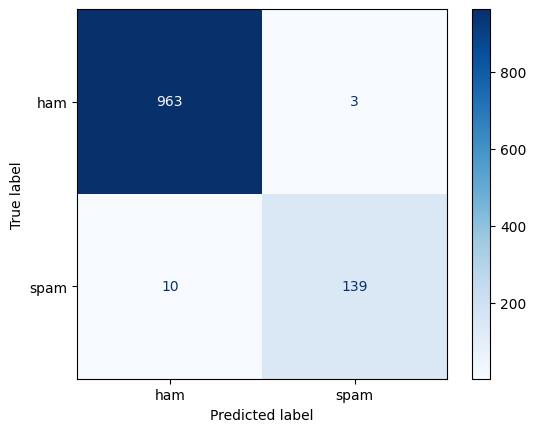

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

## Task 2.3: What did it learn?

In [10]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


## Task 2.4: Character n-grams

In [11]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

# Robustness to spelling tricks
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print(dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


## Task 2.5: Error analysis

In [12]:
print(classification_report(y_te, char_clf.predict(X_te),
                            target_names=['ham', 'spam'], digits=3))

              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115



In [13]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

In [14]:
my_tricky = [
    'Aap ne 50000 ka inam jeeta hai, abhi claim karne ke liye reply karein',
    'Congrat5! You w0n a fr33 g1ft, txt YES to 8000 now',
]
for name, clf in [('word', word_clf), ('char', char_clf)]:
    print(name, dict(zip(my_tricky, clf.predict_proba(my_tricky)[:, 1].round(2))))

word {'Aap ne 50000 ka inam jeeta hai, abhi claim karne ke liye reply karein': np.float64(0.6), 'Congrat5! You w0n a fr33 g1ft, txt YES to 8000 now': np.float64(0.86)}
char {'Aap ne 50000 ka inam jeeta hai, abhi claim karne ke liye reply karein': np.float64(0.66), 'Congrat5! You w0n a fr33 g1ft, txt YES to 8000 now': np.float64(0.9)}


### Part 2: Write it

**Results** (test set of 1,115 messages)
- Word 1-2 grams: macro-F1 0.974, spam precision 0.979, spam recall 0.933 (12,128 features)
- Char 2-5 grams: macro-F1 0.982, spam precision 0.986, spam recall 0.953 (36,449 features)
- The char model is slightly better and misses fewer spam messages, but it has three times as many features. "Always ham" would get 0.866 accuracy, so both models are far above that baseline.

**Top features**
- Most spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
- Most ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da
- Most spam features are sensible: calls to action ("call", "txt", "reply", "claim", "stop"), prize wording ("free") and web or phone cues ("www", "uk", "mobile"). Some look like shortcuts: "to" and "your" are ordinary function words, and "gt" and "lt" in the ham list are leftovers of ">" and "<" encoded as HTML in this dataset, not real meaning.

**Errors (word model, 13 of 1,115):** 10 missed spam and 3 false alarms.
- Model errors (7): rows 3979, 2821, 5, 2351, 1268, 152 and 573. Some are plain spam (5, 2351, 1268) that scored 0.41 to 0.46, just under the threshold. Rows 152 ("Ok... Ur typical reply...") and 573 ("Waiting for your call.") are clearly ham but contain the strong spam features "reply" and "call", which is a shortcut.
- Label errors (2): rows 750 (a joke about old ladies and tattoos) and 1429 (an ad for an arsenal dartboard) read like normal messages labelled spam.
- Genuinely ambiguous (4): rows 2246 (a warning about scams), 3358 (a personal-sounding message with a premium number), 5449 (a joke subscription message) and 5044 (a job offer that reads like solicitation).

**My tricky messages**
- Roman Urdu spam ("Aap ne 50000 ka inam jeeta hai..."): word 0.60, char 0.66
- Disguised English spam ("Congrat5! You w0n a fr33 g1ft..."): word 0.86, char 0.90
- The lab's tricky messages with the char model: "W1N a FR33 pr1ze!! txt CLAIM now" scored 0.85 (spam, correct) and "kal milte hain, 5 baje" scored 0.12 (ham, correct).
- Both models caught my two spam messages, but the Roman Urdu one with much lower confidence. The char model scored higher on both, because pieces like "claim" and "txt" survive spelling tricks.

# Part 3: Named Entity Recognition, Measured

## Task 3.1: Out of the box

In [15]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


## Task 3.2: Score against a gold set

In [16]:
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model):
    tp = fp = fn = 0
    for s, g in zip(sentences, gold):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('spaCy out of the box:', ner_scores(nlp))

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


## Task 3.3: Add rules before the statistical model

In [17]:
nlp_base = spacy.load('en_core_web_sm')   # untouched copy for "before" scores
nlp = spacy.load('en_core_web_sm')        # this one gets the rules

ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy out of the box :', ner_scores(nlp_base))
print('spaCy + entity ruler :', ner_scores(nlp))

spaCy out of the box : {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}
spaCy + entity ruler : {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


In [18]:
print(len(my_sentences))
for i, s in enumerate(my_sentences):
    print(i, s)

10
0 Inspector Imran Sheikh at Pakistan Steel Mills, Karachi reported scratches on coil 4417 on 12 September 2026.
1 The supplier Aisha Metals billed PKR 120,000 for the damaged steel sheets on 15/10/2026.
2 Engineer Sana Malik from Lahore found crazing on the rolled strip on Monday.
3 Amreli Steels approved a repair budget of Rs. 85,000 for supervisor Kamran Raza.
4 Quality manager Tariq Mehmood at Faisalabad Rolling Mill rejected batch 2205 on 03/11/2026.
5 Inspector Hina Qureshi of Ittefaq Foundry, Gujranwala logged pitted surface defects on 20 August 2026.
6 Master Steel paid PKR 310,500 to technician Zubair Ali in Sialkot on 07/12/2026.
7 Dr. Nadeem Akhtar visited International Steels Limited, Karachi on Friday to review inclusion defects.
8 The inspection report from Mughal Steel, Lahore lists a penalty of Rs. 45,000 due on 28/02/2027.
9 Supervisor Farhan Iqbal reported rolled-in scale at Kohat Steel Works on 5 January 2027.


In [19]:
my_gold = [
    # sentences 1-5: used to write rules
    {('Imran Sheikh', 'PERSON'), ('Pakistan Steel Mills', 'ORG'),
     ('Karachi', 'GPE'), ('12 September 2026', 'DATE')},
    {('Aisha Metals', 'ORG'), ('PKR 120,000', 'MONEY'),
     ('15/10/2026', 'DATE')},
    {('Sana Malik', 'PERSON'), ('Lahore', 'GPE'), ('Monday', 'DATE')},
    {('Amreli Steels', 'ORG'), ('Rs. 85,000', 'MONEY'),
     ('Kamran Raza', 'PERSON')},
    {('Tariq Mehmood', 'PERSON'), ('Faisalabad Rolling Mill', 'ORG'),
     ('03/11/2026', 'DATE')},

    # sentences 6-10: held out, used only for testing
    {('Hina Qureshi', 'PERSON'), ('Ittefaq Foundry', 'ORG'),
     ('Gujranwala', 'GPE'), ('20 August 2026', 'DATE')},
    {('Master Steel', 'ORG'), ('PKR 310,500', 'MONEY'),
     ('Zubair Ali', 'PERSON'), ('Sialkot', 'GPE'), ('07/12/2026', 'DATE')},
    {('Nadeem Akhtar', 'PERSON'), ('International Steels Limited', 'ORG'),
     ('Karachi', 'GPE'), ('Friday', 'DATE')},
    {('Mughal Steel', 'ORG'), ('Lahore', 'GPE'),
     ('Rs. 45,000', 'MONEY'), ('28/02/2027', 'DATE')},
    {('Farhan Iqbal', 'PERSON'), ('Kohat Steel Works', 'ORG'),
     ('5 January 2027', 'DATE')},
]

print(len(my_gold), [len(g) for g in my_gold])

# Safety check: every gold text must appear exactly in its sentence
for i, (s, g) in enumerate(zip(my_sentences, my_gold)):
    for text, label in g:
        if text not in s:
            print(f'PROBLEM in sentence {i}: "{text}" not found')
print('check done')

10 [4, 3, 3, 3, 3, 4, 5, 4, 4, 3]
check done


In [20]:
def score_set(nlp_model, sents, golds):
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3)}

print('first 5 (rule-writing set), no rules:',
      score_set(nlp_base, my_sentences[:5], my_gold[:5]))
print('last 5  (held-out set), no rules    :',
      score_set(nlp_base, my_sentences[5:], my_gold[5:]))

first 5 (rule-writing set), no rules: {'precision': 0.471, 'recall': 0.5, 'f1': 0.485}
last 5  (held-out set), no rules    : {'precision': 0.684, 'recall': 0.65, 'f1': 0.667}


In [21]:
for i, (s, g) in enumerate(zip(my_sentences, my_gold)):
    pred = {(e.text, e.label_) for e in nlp_base(s).ents}
    print(f'[{i}] {s}')
    print('   missed (in gold, not predicted):', sorted(g - pred))
    print('   wrong  (predicted, not in gold):', sorted(pred - g))

[0] Inspector Imran Sheikh at Pakistan Steel Mills, Karachi reported scratches on coil 4417 on 12 September 2026.
   missed (in gold, not predicted): [('Karachi', 'GPE')]
   wrong  (predicted, not in gold): [('4417', 'DATE'), ('Karachi', 'ORG')]
[1] The supplier Aisha Metals billed PKR 120,000 for the damaged steel sheets on 15/10/2026.
   missed (in gold, not predicted): [('15/10/2026', 'DATE'), ('Aisha Metals', 'ORG'), ('PKR 120,000', 'MONEY')]
   wrong  (predicted, not in gold): [('15/10/2026', 'GPE'), ('Aisha Metals', 'PERSON'), ('PKR 120,000', 'ORG')]
[2] Engineer Sana Malik from Lahore found crazing on the rolled strip on Monday.
   missed (in gold, not predicted): []
   wrong  (predicted, not in gold): []
[3] Amreli Steels approved a repair budget of Rs. 85,000 for supervisor Kamran Raza.
   missed (in gold, not predicted): [('Amreli Steels', 'ORG'), ('Rs. 85,000', 'MONEY')]
   wrong  (predicted, not in gold): [('85,000', 'CARDINAL'), ('Amreli Steels', 'PERSON')]
[4] Quality man

## Part 3, write rules from sentences 1 to 5 only, then test on 6 to 10

In [22]:
nlp_domain = spacy.load('en_core_web_sm')
ruler_d = nlp_domain.add_pipe('entity_ruler', before='ner')
ruler_d.add_patterns([
    # company names seen in sentences 1-5
    {'label': 'ORG', 'pattern': 'Aisha Metals'},
    {'label': 'ORG', 'pattern': 'Amreli Steels'},
    {'label': 'ORG', 'pattern': 'Faisalabad Rolling Mill'},
    # cities seen in sentences 1-5
    {'label': 'GPE', 'pattern': 'Karachi'},
    {'label': 'GPE', 'pattern': 'Lahore'},
    # money: PKR / Rs / Rs. followed by a number
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    # dates written dd/mm/yyyy
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('rules added')

rules added


### before and after scores

In [23]:
print('first 5, no rules  :', score_set(nlp_base,   my_sentences[:5], my_gold[:5]))
print('first 5, with rules:', score_set(nlp_domain, my_sentences[:5], my_gold[:5]))
print()
print('last 5,  no rules  :', score_set(nlp_base,   my_sentences[5:], my_gold[5:]))
print('last 5,  with rules:', score_set(nlp_domain, my_sentences[5:], my_gold[5:]))

first 5, no rules  : {'precision': 0.471, 'recall': 0.5, 'f1': 0.485}
first 5, with rules: {'precision': 0.889, 'recall': 1.0, 'f1': 0.941}

last 5,  no rules  : {'precision': 0.684, 'recall': 0.65, 'f1': 0.667}
last 5,  with rules: {'precision': 0.9, 'recall': 0.9, 'f1': 0.9}


### what errors remain after the rules

In [24]:
for i, (s, g) in enumerate(zip(my_sentences, my_gold)):
    pred = {(e.text, e.label_) for e in nlp_domain(s).ents}
    print(f'[{i}] {s}')
    print('   missed:', sorted(g - pred))
    print('   wrong :', sorted(pred - g))

[0] Inspector Imran Sheikh at Pakistan Steel Mills, Karachi reported scratches on coil 4417 on 12 September 2026.
   missed: []
   wrong : [('4417', 'DATE')]
[1] The supplier Aisha Metals billed PKR 120,000 for the damaged steel sheets on 15/10/2026.
   missed: []
   wrong : []
[2] Engineer Sana Malik from Lahore found crazing on the rolled strip on Monday.
   missed: []
   wrong : []
[3] Amreli Steels approved a repair budget of Rs. 85,000 for supervisor Kamran Raza.
   missed: []
   wrong : []
[4] Quality manager Tariq Mehmood at Faisalabad Rolling Mill rejected batch 2205 on 03/11/2026.
   missed: []
   wrong : [('2205', 'DATE')]
[5] Inspector Hina Qureshi of Ittefaq Foundry, Gujranwala logged pitted surface defects on 20 August 2026.
   missed: [('Ittefaq Foundry', 'ORG')]
   wrong : [('Foundry', 'ORG')]
[6] Master Steel paid PKR 310,500 to technician Zubair Ali in Sialkot on 07/12/2026.
   missed: [('Sialkot', 'GPE')]
   wrong : [('Sialkot', 'PERSON')]
[7] Dr. Nadeem Akhtar visite

### Part 3: Write it

**Provided sentences:** F1 0.533 (P 0.571, R 0.500) out of the box, then 0.875 (P 0.875, R 0.875) after the entity ruler with 7 patterns.

**My domain (steel inspection):**
- First 5 (rules written from these): F1 0.485 before, 0.941 after
- Last 5 (held out): F1 0.667 before (P 0.684, R 0.650), 0.900 after (P 0.900, R 0.900)

**What spaCy got wrong out of the box:** company names read as PERSON (Aisha Metals, Amreli Steels), dd/mm/yyyy dates labelled GPE, PKR and Rs. amounts split or mislabelled, and Pakistani cities labelled ORG or PERSON.

**Errors that remain after rules:**
1. Coil and batch numbers (4417, 2205) labelled DATE. This is a structural error: a filter or regex that checks the preceding word ("coil", "batch") fixes it better than another entity pattern.
2. "Ittefaq Foundry" and "Sialkot" were never seen when I wrote the rules.

**Rules, a regex or a model?** More rules fix a closed list (my 3 mills, a list of cities) but break on every new name, so I would not rely on them alone. A regex is best for the number problem. For unseen company and city names, a model trained on my own annotated data generalises better, but 10 sentences is too few, so I would need hundreds of annotated reports first.

# Part 4: Regex Fields with Negative Tests

In [30]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # my domain patterns (steel inspection)
    'coil':    r'\bcoil\s+(\d{3,6})\b',
    'batch':   r'\bbatch\s+(\d{3,6})\b',
    'defect':  r'\b(crazing|inclusion|patches|pitted surface|rolled-in scale|scratches)\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

In [31]:
tests = [
    # (text, fields that MUST be found, fields that must NOT be found)
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', {'cnic', 'mobile'}, set()),
    ('Total Rs. 12,500.50 paid on 05/10/2026', {'amount', 'date'}, set()),
    ('Invoice No. 4417 from info@engro.com.pk', {'invoice', 'email'}, set()),
    ('Found scratches on coil 4417 in batch 2205', {'coil', 'batch', 'defect'}, set()),
    # negative tests (nothing should match)
    ('Order 12345678901234 shipped', set(), {'cnic'}),
    ('Room 0300 on floor 3', set(), {'mobile'}),
    ('Coil 12 was moved to shelf 3', set(), {'coil'}),         # too few digits
    ('Reference coil 4417896 is archived', set(), {'coil'}),   # too many digits
    ('A batch of 25 sheets arrived', set(), {'batch'}),        # no batch number
]

all_pass = True
for text, must, must_not in tests:
    found = set(extract_fields(text))
    ok = must <= found and not (must_not & found)
    all_pass = all_pass and ok
    print('PASS' if ok else 'FAIL', sorted(found), '<-', text)
print('ALL PASS' if all_pass else 'SOME FAILED')

PASS ['cnic', 'mobile'] <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS ['amount', 'date'] <- Total Rs. 12,500.50 paid on 05/10/2026
PASS ['email', 'invoice'] <- Invoice No. 4417 from info@engro.com.pk
PASS ['batch', 'coil', 'defect'] <- Found scratches on coil 4417 in batch 2205
PASS [] <- Order 12345678901234 shipped
PASS [] <- Room 0300 on floor 3
PASS [] <- Coil 12 was moved to shelf 3
PASS [] <- Reference coil 4417896 is archived
PASS [] <- A batch of 25 sheets arrived
ALL PASS


In [32]:
loose = r'coil\s+\d+'
for t in ['coil 4417', 'Coil 12 was moved', 'coil 4417896 is archived']:
    print(bool(re.search(loose, t, flags=re.IGNORECASE)), '<-', t)

True <- coil 4417
True <- Coil 12 was moved
True <- coil 4417896 is archived


### Part 4: Write it

**Patterns:** the 6 provided (CNIC, mobile, amount, date, email, invoice) plus 3 for my steel-inspection domain:
- coil: `\bcoil\s+(\d{3,6})\b`
- batch: `\bbatch\s+(\d{3,6})\b`
- defect: `\b(crazing|inclusion|patches|pitted surface|rolled-in scale|scratches)\b`

**Test results:** 9 of 9 passed.
- 4 positive tests: the CNIC and mobile, amount and date, invoice and email, and coil, batch and defect fields were all found.
- 5 negative tests: a 14-digit order number was not a CNIC, "Room 0300" was not a mobile, "Coil 12" (too few digits), "coil 4417896" (too many digits) and "A batch of 25 sheets" (no batch number) all matched nothing.

**A pattern that matched too much:** my first coil pattern was `coil\s+\d+`. It matched all three test strings, including "Coil 12 was moved" and "coil 4417896 is archived", which should be rejected. I fixed it with a word boundary (`\b`) so it cannot start inside another word, and an exact digit count (`{3,6}`) so 2-digit and 7-digit numbers are ignored.

# Part 5: Character Error Rate and OCR Repair

## Task 5.1: CER and context rules

In [33]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)          # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


## Task 5.2, OCR on a synthetic invoice

In [35]:
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch
from matplotlib import font_manager

font_path = font_manager.findfont('DejaVu Sans')
print('using font:', font_path)

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font = ImageFont.truetype(font_path, 30)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(),
                        verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')

using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


### Part 5: Write it

**Task 5.1 (hand-made OCR errors):** CER 0.062, 0.059 and 0.143 before the fixes, and 0.000 for all three after `fix_ocr`. The rules turned letter O into 0 inside numbers and "N0." back into "No.".

**Task 5.2 (synthetic invoice):** raw CER 0.000, after fixes 0.000. EasyOCR read all 5 lines correctly, so the correction rules had nothing to repair here.

**Why this is easier than a real phone photo:** the image is black text on a pure white background, one clean font (DejaVu Sans, 30 pt), perfectly horizontal, with no blur, shadows, skew, noise or compression. Real phone photos have uneven lighting, perspective, motion blur, creases, stamps and sometimes handwriting, which confuse similar characters (0/O, 1/l/I, 5/S).

**What I expect on my own documents:** a clearly non-zero CER, and errors concentrated in digits and in look-alike characters. Because one wrong digit makes a whole amount or ID wrong, I should also measure field-level accuracy, not only CER. My context rules only fix letters inside numbers and the "N0." pattern, so they would not repair other mistakes.

# Part 6: Image + Text Case Record

## Task 6.1: Mask personal identifiers

In [36]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


## Task 6.2: Load your Week 6 model and build evidence functions

In [37]:
import torch
W6_PATH = '/kaggle/input/notebooks/maaziii29/maaz-imtiaz-week6/week6_model.pt'
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)

print('keys     :', list(ckpt.keys()))
print('backbone :', ckpt['backbone'])
print('classes  :', ckpt['classes'])
print('grayscale:', ckpt['grayscale'])
print('img_size :', ckpt['img_size'])

keys     : ['state_dict', 'classes', 'backbone', 'img_size', 'grayscale']
backbone : resnet18
classes  : ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
grayscale: True
img_size : 224


## Task 6.3: One transparent record

In [39]:
import os
imgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    if '/notebooks/' in root:
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            imgs.append(os.path.join(root, f))
print(len(imgs))
for p in imgs[:10]:
    print(p)

0


In [40]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image

classes = ckpt['classes']

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

URGENT = ['crack', 'crazing', 'scratch', 'spreading', 'deep', 'pitting']

def text_evidence(note):
    doc = nlp_domain(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

print('model loaded, classes:', classes)

model loaded, classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [42]:
imgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    if '/notebooks/' in root:
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            imgs.append(os.path.join(root, f))
print(len(imgs))
for p in imgs[:10]:
    print(p)

1800
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_1.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_10.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_100.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_101.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_102.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_103.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_104.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_105.jpg
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing/crazin

## Part 6, build your case record

## pick a validation image

In [43]:
val_imgs = {c: [] for c in classes}
for p in imgs:
    if '/validation/' in p.replace('\\', '/'):
        for c in classes:
            if f'/{c}/' in p.replace('\\', '/'):
                val_imgs[c].append(p)

for c in classes:
    print(c, len(val_imgs[c]))

EXAMPLE_IMAGE = sorted(val_imgs['crazing'])[0]   # change 'crazing' if you pick another class
print('EXAMPLE_IMAGE =', EXAMPLE_IMAGE)

crazing 60
inclusion 60
patches 60
pitted_surface 60
rolled-in_scale 60
scratches 60
EXAMPLE_IMAGE = /kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/validation/images/crazing/crazing_241.jpg


In [44]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)            # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

note = ('Inspector Imran Sheikh at Pakistan Steel Mills, Karachi found fine '
        'cracks spreading on coil 4417 on 12/09/2026. Contact mobile 0300-1234567.')
rec = case_record(EXAMPLE_IMAGE, note, positive='crazing')
print(json.dumps(rec, indent=2, ensure_ascii=False))

# leak check: none of these should print True
print('phone digits leaked:', '1234567' in json.dumps(rec))

{
  "image": "crazing_241.jpg",
  "image_probabilities": {
    "crazing": 1.0,
    "inclusion": 0.0,
    "patches": 0.0,
    "pitted_surface": 0.0,
    "rolled-in_scale": 0.0,
    "scratches": 0.0
  },
  "note_masked": "Inspector Imran Sheikh at Pakistan Steel Mills, Karachi found fine cracks spreading on coil 4417 on 12/09/2026. Contact mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Imran Sheikh",
        "PERSON"
      ],
      [
        "Pakistan Steel Mills",
        "ORG"
      ],
      [
        "Karachi",
        "GPE"
      ],
      [
        "4417",
        "DATE"
      ],
      [
        "12/09/2026",
        "DATE"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ],
      "coil": [
        "4417"
      ]
    },
    "urgent_terms": [
      "crack",
      "spreading"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(crazing) = 1.00",
    "note mentions: crack, spreading"
  ],
  "disclaimer": "Decision suppo

## Part 6, the disagreement case

In [45]:
# Case A: a non-crazing image, but the note describes spreading cracks
other_image = sorted(val_imgs['patches'])[0]
recA = case_record(other_image, note, positive='crazing')
print('A image   :', recA['image'], '| P(crazing) =', recA['image_probabilities']['crazing'])
print('A decision:', recA['decision'], '|', recA['reasons'])

# Case B: a crazing image, but the note says the surface is normal
routine_note = ('Inspector Imran Sheikh at Pakistan Steel Mills, Karachi checked '
                'coil 4417 on 12/09/2026. Surface looks normal.')
recB = case_record(EXAMPLE_IMAGE, routine_note, positive='crazing')
print('B image   :', recB['image'], '| P(crazing) =', recB['image_probabilities']['crazing'])
print('B decision:', recB['decision'], '|', recB['reasons'])

A image   : patches_241.jpg | P(crazing) = 0.0
A decision: REFER | ['note mentions: crack, spreading']
B image   : crazing_241.jpg | P(crazing) = 1.0
B decision: REFER | ['image model: P(crazing) = 1.00']


### Part 6: Write it

**Record:** image crazing_241.jpg (validation), P(crazing) = 1.00. Decision REFER with 2 reasons.

**Do the reasons make sense?** Yes. The image model is certain (1.00 ≥ 0.5 threshold), and the note mentions "crack" and "spreading", which are on my urgent list. Both point the same way, and the record shows which evidence triggered the decision.

**A wrong entity:** "4417" (a coil number) was labelled DATE. For this decision it is harmless, because REFER came from the image probability and urgent terms, not from entities. It would be harmful if a database stored the entity list, because the coil ID would be filed as a date. The regex field `coil: ['4417']` has the right value, so IDs are better extracted with regex than with NER.

**Privacy:** the mobile number was masked to [PHONE] before extraction, and a leak check for the digits printed False.

**When image and note disagree:**
- Case A (patches image, note says cracks are spreading): P(crazing) = 0.0, decision REFER, reason "note mentions: crack, spreading" only.
- Case B (crazing image, note says surface looks normal): P(crazing) = 1.0, decision REFER, reason "image model: P(crazing) = 1.00" only.

The system should not silently pick one side. It should refer the case, mark the disagreement in the reasons ("image and note disagree"), and let a qualified person decide. That is safest for the class I must not miss, because missing a spreading crack costs more than a false referral. A disagreement is itself useful information.

## Conclusion

This lab gave my Project 2 system the ability to read text and combine it with the image evidence from Week 6. Each component was measured rather than assumed.

**Text representation and classification.** I reproduced TF-IDF by hand and matched scikit-learn exactly (win 0.584, free 0.445, cash 0.584, now 0.345). On the SMS spam data, the character 2-5 gram model beat the word 1-2 gram model: macro-F1 0.982 vs 0.974, and spam recall 0.953 vs 0.933. Both are far above the 0.866 "always ham" baseline. Character n-grams also scored my disguised and Roman Urdu spam messages as spam (0.66 and 0.90).

**Entity extraction.** Out of the box, spaCy scored F1 0.533 on the provided sentences and 0.667 on my held-out steel-inspection sentences. Entity rules raised these to 0.875 and 0.900. The remaining errors were coil and batch numbers labelled as dates, and company and city names the rules had never seen.

**Regex and OCR.** My domain regex patterns passed all 9 tests, including 5 negative tests. Context rules brought CER on the hand-made OCR errors from 0.062, 0.059 and 0.143 to 0.000. The synthetic invoice already had CER 0.000, but a real photo will be much harder.

**Multimodal record.** The final JSON record combined my Week 6 model (P(crazing) = 1.00) with the note's evidence, gave a REFER decision with two clear reasons, and masked the phone number before extraction (leak check: False).

**Main lesson.** Every component needs a number, and rules, regex and models each fit different problems. Personal data must be masked before any extraction, and the system supports a human decision rather than replacing it.